# Volatility Dynamics 04b — repaired volatility conditioning for q99 precursors

Claude review (**VD 010**). Module 04's matching failed its own check (`realized_vol_30m` retention 1.00, `realized_vol_1h` 0.95): with ~15 exact-slot candidates per event and six single-bar $r^2$ values, it could not condition on the volatility environment.

04b (details in `volatility_q99_matching_b.py`):

- causal environment: $\log\overline{r^2}$ over the previous 15m / 1h / 4h / 24h (**M1**); **M2** adds $\log\overline{\text{range}}$ over 15m / 1h;
- controls from a ±30 min clock window across all dates, ≥4h from the event (~220–250 candidates instead of ~15);
- **bias correction**: each control value is shifted by $\hat\beta^\top(e_{\text{event}}-e_{\text{control}})$ (per asset, lag, field; log scale) before ranking;
- pre-registered statistic $W$ = mean percentile over −60…−5 min (no best-lag pick); day-relabel placebo band.

**Pre-registered gate:** retention $|W-0.5|/|W_{\text{clock}}-0.5|$ of `realized_vol_1h` and `realized_vol_4h` ≤ 0.20 under both M1_bc and M2_bc, else nothing is interpreted.
**Reading rule:** non-range fields judged under **M2_bc** (decided on synthetic data where range/volume carry only volatility). A field *survives volatility conditioning* only if its $W$ differs from the placebo distribution with **Holm-adjusted** $p<0.05$ (across all judged fields) on the same side of 0.5 as its clock-only $W$. `intrabar_range_bps` is a better volatility estimator than return RV and is reported as not testable.

**Survival is necessary, not sufficient**: a field that measures latent volatility more precisely than return RV + range history (high-count activity, smooth IV level) also survives in a volatility-only synthetic world. Surviving fields go to a forecast test next.

In [1]:
from pathlib import Path
import json, os, sys, time, warnings
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 300)
pd.set_option('display.max_rows', 300)

load_dotenv()
DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
DB_PATH = DATA_ROOT / 'database' / 'research.duckdb'
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    raise RuntimeError('Repository root not found.')
SRC = PROJECT_ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from data_engineering.modeling import volatility_vd_b_core as vb
from data_engineering.modeling import volatility_q99_matching_b as mb
START = os.getenv('VD4B_START', '').strip() or None
END = os.getenv('VD4B_END', '').strip() or None
ASSETS = [x.strip().upper() for x in os.getenv('VD4B_ASSETS', '').split(',') if x.strip()]
N_PERM = int(os.getenv('VD4B_N_PERM', '200'))
SEED = int(os.getenv('VD4B_SEED', '4040'))
OUT = PROJECT_ROOT / 'notebooks' / 'Volatility_Dynamics' / '04b'
OUT.mkdir(parents=True, exist_ok=True)
print('core', vb.VERSION, vb.selftest())
print('04b', mb.VERSION, mb.selftest())


core 0.1.0 {'dense_grid': True, 'us_timestamp_backing': True, 'causal_window_mean': True, 'q99_onsets': True, 'day_relabel_placebo': True, 'no_self_control': True}
04b 0.1.0 {'bias_corrected_matching': True, 'gate_passes_on_vol_only_world': True, 'volume_not_flagged_when_only_vol_drives_it': True, 'placebo_null': True}


In [2]:
def qident(name):
    return '"' + str(name).replace('"', '""') + '"'

def load_frame(columns, start=None, end=None, assets=None):
    cols = list(dict.fromkeys(['state_time', 'underlying', 'return_5m'] + list(columns)))
    where = []
    if start:
        ts = pd.Timestamp(start)
        ts = ts.tz_localize('UTC') if ts.tzinfo is None else ts.tz_convert('UTC')
        where.append(f"state_time >= TIMESTAMPTZ '{ts.isoformat()}'")
    if end:
        ts = pd.Timestamp(end)
        ts = ts.tz_localize('UTC') if ts.tzinfo is None else ts.tz_convert('UTC')
        where.append(f"state_time < TIMESTAMPTZ '{(ts + pd.Timedelta(days=1)).isoformat()}'")
    if assets:
        where.append('underlying IN (' + ','.join(repr(x) for x in assets) + ')')
    sql = ('SELECT ' + ', '.join(qident(c) for c in cols) + ' FROM time_series_feature_state'
           + ('' if not where else ' WHERE ' + ' AND '.join(where)) + ' ORDER BY underlying, state_time')
    con = duckdb.connect(str(DB_PATH), read_only=True)
    try:
        df = con.execute(sql).df()
    finally:
        con.close()
    if df.empty:
        raise RuntimeError('No rows found.')
    df['state_time'] = pd.to_datetime(df['state_time'], utc=True)
    if df.duplicated(['underlying', 'state_time']).any():
        raise RuntimeError('Duplicate asset/timestamp rows.')
    print(f'rows {len(df):,} | assets {sorted(df.underlying.unique())} | {df.state_time.min()} -> {df.state_time.max()}')
    return df.reset_index(drop=True)

def schema_columns():
    con = duckdb.connect(str(DB_PATH), read_only=True)
    try:
        return con.execute('DESCRIBE time_series_feature_state').df()
    finally:
        con.close()

schema = schema_columns()
contract, features = mb.analysis_features(schema['column_name'].astype(str))
display(contract)
if 'intrabar_range_bps' not in features:
    raise RuntimeError('intrabar_range_bps is required for the M2 environment.')
df = load_frame(features, START, END, ASSETS)


,feature,role,present,in_matching_set_M2
0,intrabar_range_bps,primary_candidate,True,True
1,volume_usd,primary_candidate,True,False
2,trade_count,primary_candidate,True,False
3,option_iv_atm_forward,primary_candidate,True,False
4,iv_put_25d,primary_candidate,True,False
5,iv_call_25d,primary_candidate,True,False
6,book_twa_spread_bps,primary_candidate,True,False
7,book_update_count,primary_candidate,True,False
8,book_obi_20_raw_zero_cross_count,primary_candidate,True,False
9,book_obi_20_transition_count,primary_candidate,True,False


rows 42,336 | assets ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP'] | 2026-09-19 08:00:00+00:00 -> 2026-10-10 07:55:00+00:00


In [3]:
grid = vb.build_grid(df)
thr = vb.q99_thresholds(grid)                    # full-sample, as Modules 03/04
tail = vb.tail_flags(grid, thr)
event_rows = np.flatnonzero(vb.onset_flags(grid, tail))
eligible = vb.eligible_origins(grid, tail)
env, env_cols, env_spec = mb.environment(grid)
X = grid.feature_matrix(features)
events = vb.event_table(grid, event_rows, thr)
print('asset-event onsets:', len(event_rows), '| unique timestamps:', events.event_time.nunique())
display(env_spec)


asset-event onsets: 337 | unique timestamps: 198


,column,start_bar,end_bar,min_finite_bars
0,env_lrv_15m,-3,-1,2
1,env_lrv_1h,-12,-1,9
2,env_lrv_4h,-48,-1,36
3,env_lrv_24h,-288,-1,216
4,env_lrange_15m,-3,-1,2
5,env_lrange_1h,-12,-1,9


In [4]:
t0 = time.time()
res = mb.observed_study(grid, X, features, event_rows, eligible, env, env_cols)
print(f'observed study {time.time()-t0:.1f}s')
display(res['support'].groupby('control_set')[['n_candidate_pool','n_controls_selected','median_selected_distance']].describe().round(2).T)
display(res['balance'].pivot(index='env_column', columns='control_type', values='median_event_minus_control').round(3))
gate = mb.matching_gate(res['window_summary'])
print(json.dumps(gate, indent=2))


observed study 4.9s


control_set                         M1      M2
n_candidate_pool         count  337.00  337.00
                         mean   190.10  147.82
                         std     37.91   76.34
                         min      0.00    0.00
                         25%    180.00  154.00
                         50%    194.00  176.00
                         75%    211.00  197.00
                         max    228.00  228.00
n_controls_selected      count  337.00  337.00
                         mean     7.76    6.51
                         std      1.36    3.11
                         min      0.00    0.00
                         25%      8.00    8.00
                         50%      8.00    8.00
                         75%      8.00    8.00
                         max      8.00    8.00
median_selected_distance count  327.00  275.00
                         mean     0.42    0.47
                         std      0.22    0.28
                         min      0.12    0.14
                         25%      0.28    0.31
                         50%      0.37    0.39
                         75%      0.50    0.55
                         max      2.20    2.48

control_type,M1_bc,M1_matched,M2_bc,clock_only
env_column,,,,
env_lrange_15m,0.184,0.184,0.086,0.515
env_lrange_1h,0.096,0.096,0.073,0.315
env_lrv_15m,0.068,0.068,0.018,0.950
env_lrv_1h,0.048,0.048,0.066,0.580
env_lrv_24h,0.009,0.009,-0.002,0.159
env_lrv_4h,0.054,0.054,0.045,0.387


{
  "gate": "retention of ['realized_vol_1h', 'realized_vol_4h'] <= 0.2 under ['M1_bc', 'M2_bc']",
  "retention": {
    "M1_bc:realized_vol_1h": 0.11880754804477207,
    "M1_bc:realized_vol_4h": 0.10256010203227203,
    "M2_bc:realized_vol_1h": 0.06600180118184283,
    "M2_bc:realized_vol_4h": 0.014402498256856754
  },
  "matching_gate_pass": true,
  "judging_design_default": "M2_bc",
  "judging_design_intrabar_range": "M1_bc"
}


In [5]:
t0 = time.time()
null = mb.placebo_window_null(grid, X, event_rows, eligible, env, env_cols, n_perm=N_PERM, seed=SEED,
                              Z=res['Z'], adjustment=res['adjustment'], progress_every=25)
print(f'{N_PERM} placebo runs in {time.time()-t0:.0f}s')
summary = mb.attach_null(res['window_summary'], features, null)
verdicts = mb.candidate_verdicts(summary, contract, gate['matching_gate_pass'])
display(summary.pivot(index='feature', columns='control_type', values='window_mean_percentile').round(3))
display(verdicts.round(3))


placebo 25/200
placebo 50/200
placebo 75/200
placebo 100/200
placebo 125/200
placebo 150/200
placebo 175/200
placebo 200/200
200 placebo runs in 30s


control_type,M1_bc,M1_matched,M2_bc,clock_only
feature,,,,
book_obi_20_path_roughness_per_min,0.608,0.601,0.537,0.680
book_obi_20_raw_zero_cross_count,0.569,0.571,0.453,0.678
book_obi_20_raw_zero_cross_rate,0.557,0.551,0.444,0.649
book_obi_20_transition_count,0.557,0.543,0.535,0.637
book_twa_spread_bps,0.540,0.560,0.534,0.590
book_update_count,0.487,0.516,0.462,0.602
intrabar_range_bps,0.518,0.562,0.480,0.650
iv_call_25d,0.550,0.592,0.552,0.674
iv_put_25d,0.533,0.586,0.539,0.678


,feature,role,judging_design,clock_only_W,judging_W,placebo_q025,placebo_q975,placebo_z,placebo_p_normal,n_unique_event_times,retention_vs_clock_only,holm_p,verdict
0,intrabar_range_bps,primary_candidate,M1_bc,0.650,0.518,0.463,0.523,1.674,0.094,164.0,0.119,NaN,volatility_estimator_not_testable
1,volume_usd,primary_candidate,M2_bc,0.616,0.510,0.448,0.549,0.383,0.701,146.0,0.090,1.0,explained_by_volatility_or_noise
2,trade_count,primary_candidate,M2_bc,0.632,0.483,0.437,0.544,-0.292,0.770,146.0,0.126,1.0,explained_by_volatility_or_noise
3,option_iv_atm_forward,primary_candidate,M2_bc,0.664,0.533,0.425,0.605,0.454,0.650,146.0,0.199,1.0,explained_by_volatility_or_noise
4,iv_put_25d,primary_candidate,M2_bc,0.678,0.539,0.420,0.597,0.777,0.437,142.0,0.220,1.0,explained_by_volatility_or_noise
5,iv_call_25d,primary_candidate,M2_bc,0.674,0.552,0.421,0.607,0.993,0.321,140.0,0.299,1.0,explained_by_volatility_or_noise
6,book_twa_spread_bps,primary_candidate,M2_bc,0.590,0.534,0.436,0.577,0.760,0.447,129.0,0.375,1.0,explained_by_volatility_or_noise
7,book_update_count,primary_candidate,M2_bc,0.602,0.462,0.419,0.561,-0.734,0.463,129.0,0.367,1.0,explained_by_volatility_or_noise
8,book_obi_20_raw_zero_cross_count,primary_candidate,M2_bc,0.678,0.453,0.398,0.589,-0.727,0.467,16.0,0.261,1.0,explained_by_volatility_or_noise
9,book_obi_20_transition_count,primary_candidate,M2_bc,0.637,0.535,0.323,0.583,0.970,0.332,16.0,0.252,1.0,explained_by_volatility_or_noise


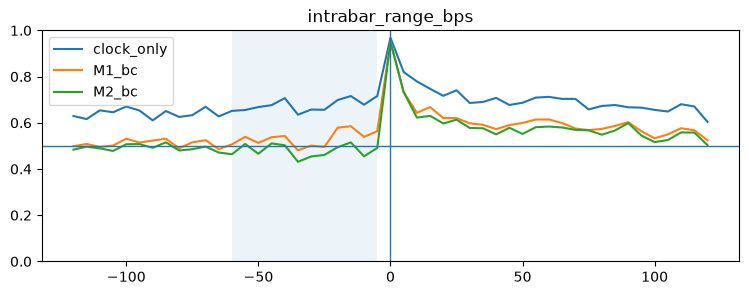

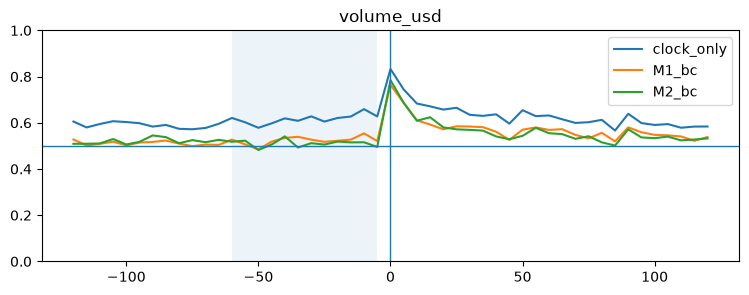

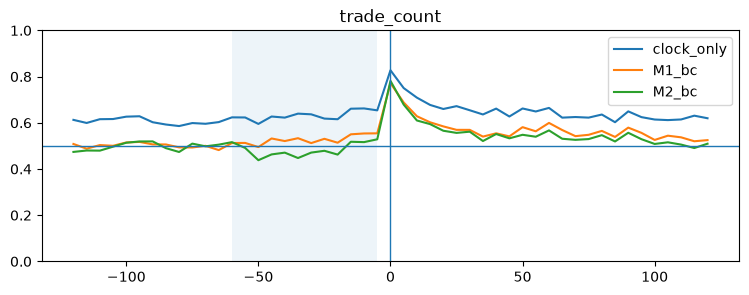

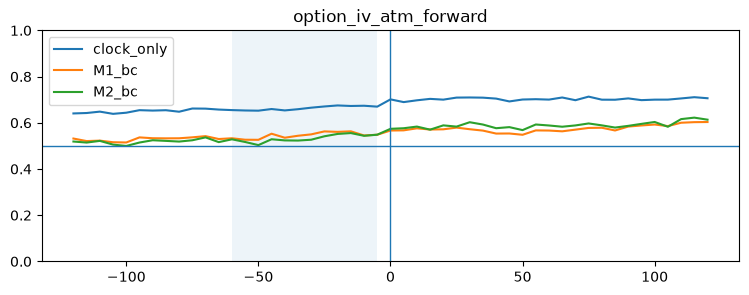

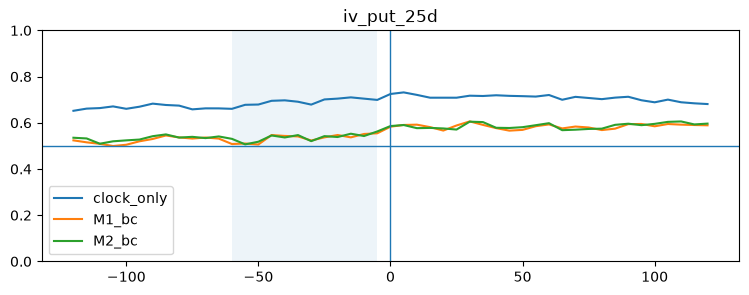

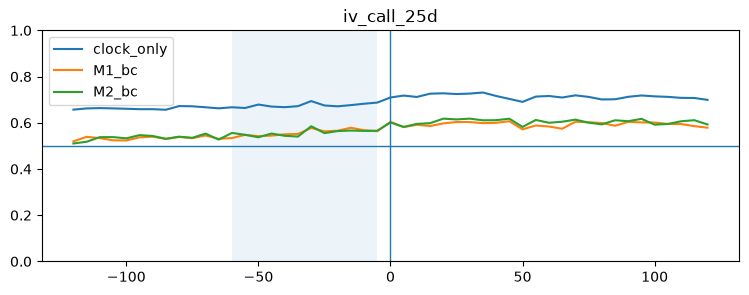

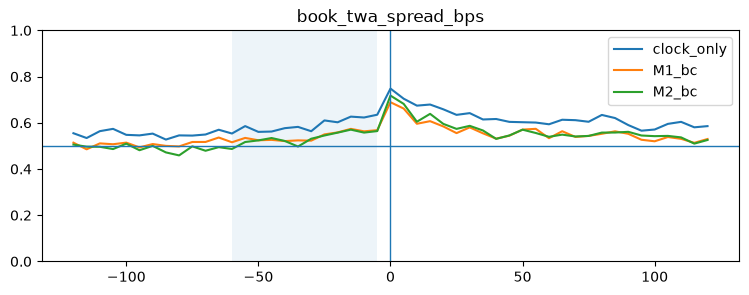

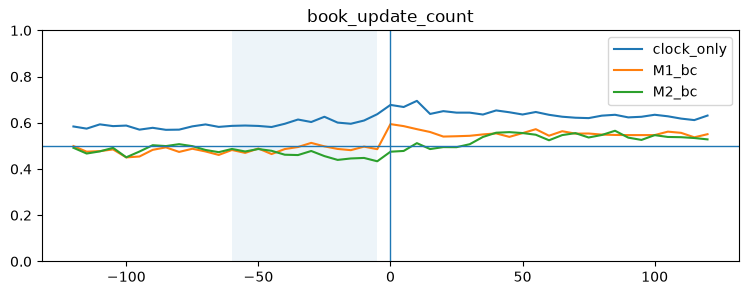

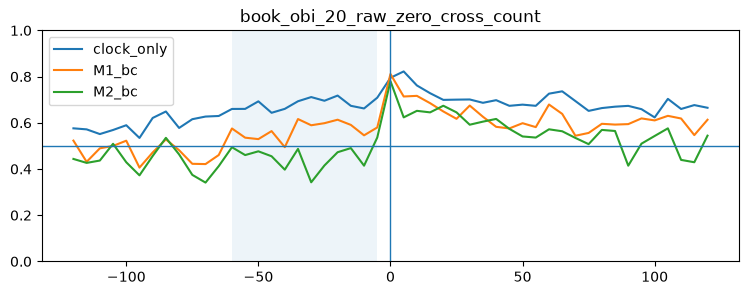

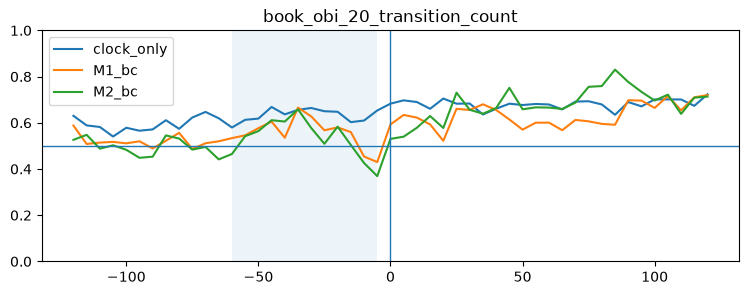

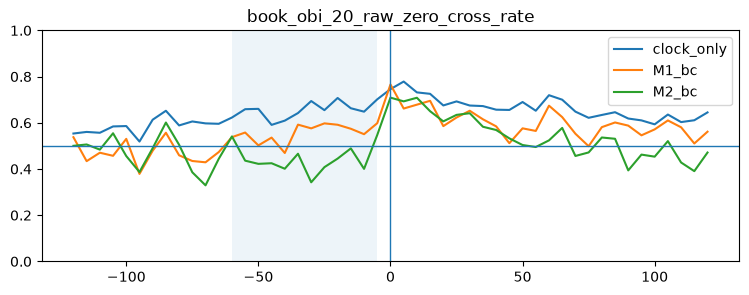

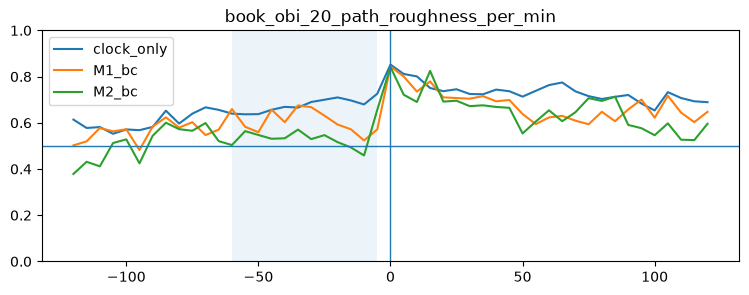

In [6]:
prof = res['profiles']
for f in [x for x in mb.PRIMARY_CANDIDATES if x in features]:
    fig, ax = plt.subplots(figsize=(9, 3))
    for ct in ['clock_only', 'M1_bc', 'M2_bc']:
        g = prof[(prof.feature == f) & (prof.control_type == ct)].sort_values('rel_min')
        if len(g):
            ax.plot(g.rel_min, g.mean_percentile, label=ct)
    ax.axhline(0.5, linewidth=1); ax.axvline(0, linewidth=1)
    ax.axvspan(-60, -5, alpha=0.08)
    ax.set_ylim(0, 1); ax.set_title(f); ax.legend()
    plt.show()


In [7]:
contract.to_csv(OUT / '04b_candidate_contract.csv', index=False)
env_spec.to_csv(OUT / '04b_env_spec.csv', index=False)
pd.DataFrame([{'underlying': k, 'q99_threshold': v} for k, v in thr.items()]).to_csv(OUT / '04b_q99_thresholds.csv', index=False)
events.to_csv(OUT / '04b_event_origins.csv', index=False)
res['support'].to_csv(OUT / '04b_match_support.csv', index=False)
res['balance'].to_csv(OUT / '04b_env_balance.csv', index=False)
res['profiles'].to_csv(OUT / '04b_profiles.csv', index=False)
summary.to_csv(OUT / '04b_window_summary.csv', index=False)
verdicts.to_csv(OUT / '04b_candidate_verdicts.csv', index=False)
(OUT / '04b_matching_gate.json').write_text(json.dumps(gate, indent=2))
meta = {
    'version': mb.VERSION, 'core_version': vb.VERSION, 'module': '04b_repaired_vol_conditioning',
    'designs': list(mb.DESIGNS), 'primary_design': mb.PRIMARY_DESIGN,
    'statistic': 'window mean percentile over rel bars -12..-1 (-60..-5 min), collapsed by timestamp',
    'clock_window_slots': mb.DEFAULT_CLOCK_WINDOW_SLOTS, 'min_separation_bars': mb.DEFAULT_MIN_SEPARATION_BARS,
    'max_controls': mb.DEFAULT_MAX_CONTROLS, 'min_controls': mb.DEFAULT_MIN_CONTROLS,
    'gate': gate, 'n_perm': N_PERM, 'seed': SEED, 'scale_kinds': res['scale_kinds'],
    'n_asset_event_onsets': int(len(event_rows)), 'n_unique_event_times': int(events.event_time.nunique()),
    'start': START or 'earliest_available', 'end': END or 'latest_available',
    'first_time': str(df.state_time.min()), 'last_time': str(df.state_time.max()), 'n_rows': int(len(df)),
}
(OUT / '04b_run_metadata.json').write_text(json.dumps(meta, indent=2))
print('wrote', OUT)


wrote D:\Projects\deribit_market_data\notebooks\Volatility_Dynamics\04b
